# Lab 7: Decision Trees and Random Forests
**30 minutes** | Student name: ______ ID: ______

**Goal for today:** Train and visualize a decision tree, tune its depth using 5-fold cross-validation, and compare it with a random forest.

**By the end of this lab, you should be able to:**
1. Fit and visualize a shallow decision tree.
2. Use GridSearchCV to select tree depth using training data only.
3. Fit a random forest and summarize their depths.
4. Compare model accuracy on a held-out test set and interpret feature importance.

Use penguins_clean.csv beside this notebook. It contains 342 penguins with four familiar body measurements and species labels. Rows missing retained values were removed from Palmer Penguins. Predict Adelie, Chinstrap, or Gentoo. Source: Allison Horst et al., Palmer Penguins, https://allisonhorst.github.io/palmerpenguins/.

## 1. Load and inspect (3 minutes)
Inspect dimensions, measurement names, species, and class counts.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
RANDOM_STATE=42
df=pd.read_csv("penguins_clean.csv")
X=df.drop(columns="species")
y=df["species"]
print(df.shape, list(X.columns), y.value_counts(), sep="\n")
display(df.head())

(342, 5)
['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,Adelie,39.1,18.7,181.0,3750.0
1,Adelie,39.5,17.4,186.0,3800.0
2,Adelie,40.3,18.0,195.0,3250.0
3,Adelie,36.7,19.3,193.0,3450.0
4,Adelie,39.3,20.6,190.0,3650.0


Observation: What are we predicting? Are the species counts balanced?

Response: ___________________________

## 2. Split data (3 min)
* Use `train_test_split` to make a stratified 75/25 split. Set `random_state=42` so the random split is reproducible: you and your instructor will get the same rows in each set, making results easier to compare. The number 42 is an arbitrary seed, not a special setting. `test_size` sets the test fraction; `stratify=y` aims to keep species proportions similar. 
* After splitting, compare the proportions in the full dataset, training set, and test set using the table in the code cell. 
Are they approximately maintained? Tune only with training data and reserve test data for final evaluation.

In [9]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=RANDOM_STATE,stratify=y)
print('Training rows:', len(X_train), 'Test rows:', len(X_test))
proportions = pd.DataFrame({
    'Full dataset': y.value_counts(normalize=True),
    'Training set': y_train.value_counts(normalize=True),
    'Test set': y_test.value_counts(normalize=True)
}).fillna(0)
display(proportions.round(3))

Training rows: 256 Test rows: 86


,Full dataset,Training set,Test set
species,,,
Adelie,0.442,0.441,0.442
Gentoo,0.360,0.359,0.360
Chinstrap,0.199,0.199,0.198


## 3. Fit and visualize a decision tree (5 min)
Create a DecisionTreeClassifier with max_depth=2 and random_state=RANDOM_STATE. Fit it on the training set, report training and test accuracy, and visualize the tree with plot_tree. Identify the root feature and explain its split in the context of penguin measurements.
Hints: 
* `max_depth=2` limits the tree to two decision levels, keeping it small enough to inspect. 
* `fit(X_train, y_train)` learns the splits.
* `predict(X_train)` and `predict(X_test)` produce class labels;
* `accuracy_score` compares predictions with the true labels.
* In `plot_tree`, `feature_names` labels split variables, `class_names` labels predictions, and `filled=True` colors nodes by predicted class.

Training Accuracy: 0.957
Test Accuracy: 0.988


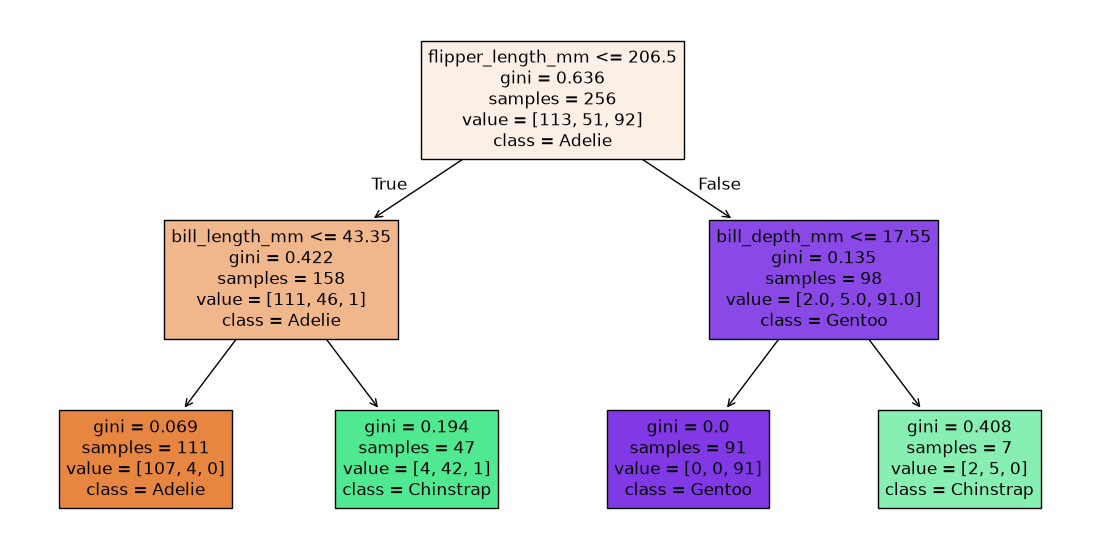

In [10]:
tree = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)

# 1. Fit the model: tree.fit(...)
tree.fit(X_train, y_train)

# 2. Predict the training and test labels with tree.predict(...)
y_train_pred = tree.predict(X_train)
y_test_pred = tree.predict(X_test)

# 3. Use accuracy_score(true_labels, predicted_labels) for each set.
train_acc = accuracy_score(y_train, y_train_pred)

#    Save the test score as baseline_test_acc for comparison in Task 4.
baseline_test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", round(train_acc, 3))
print("Test Accuracy:", round(baseline_test_acc, 3))

# 4. Draw the tree with plot_tree. Use X.columns for feature_names,
#    sorted(y.unique()) for class_names, and filled=True, rounded=True.
plt.figure(figsize=(14,7))
plot_tree(
          tree,
          feature_names=X.columns,
          class_names=[str(c) for c in sorted(y.unique())],
          filled=True)
plt.show()

Training accuracy: (107+42+91+5)/256 = 0.957
Test accuracy: 0.988
Root feature and split interpretation: The root feature is flipper_length_mm, with a threshold of 206.5 mm. Penguins with flipper lengths less than or equal to 206.5 mm go to the left branch, while those with longer flippers go to the right branch. This split helps distinguish Gentoo penguins from Adelie and Chinstrap penguins.

## 4. Tune the decision tree (5 min)
* Try `max_depth` values [1, 2, 3, 4, None] and find which works best.
* Use `GridSearchCV` with 5 folds and fit it on `X_train`, `y_train`.
* Write down the `best depth` and its average cross-validation accuracy. Then check the selected tree's accuracy on `X_test` and compare it with your depth-2 tree.
* Hints: GridSearchCV tests each depth using five parts of the training data. `best_params_` shows the chosen depth; `best_score_` shows its average cross-validation accuracy.
* Use the test set only after choosing the depth. A deeper tree makes more detailed rules, but may fit the training data too closely.

In [11]:
depth_values = [1, 2, 3, 4, None]  # None means no depth limit
tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid={'max_depth': depth_values},
    scoring='accuracy', cv=5, return_train_score=True
)

# 1. Fit the search with tree_search.fit(X_train, y_train).
tree_search.fit(X_train, y_train)

# 2. Print tree_search.best_params_ and tree_search.best_score_.
print("Best depth:", tree_search.best_params_)
print("Best CV accuracy:", round(tree_search.best_score_, 3))

# 3. Set best_tree = tree_search.best_estimator_.
best_tree = tree_search.best_estimator_

# 4. Predict y_test using best_tree.predict(X_test). Calculate accuracy
#    with accuracy_score and save it as tree_test_acc.
y_test_pred = best_tree.predict(X_test)
tree_test_acc = accuracy_score(y_test, y_test_pred)

# 5. Compare tree_test_acc with baseline_test_acc from Task 3.
print('Depth-2 Test Accuracy:', round(baseline_test_acc, 3))
print("Tuned Tree Test Accuracy:", round(tree_test_acc, 3))

Best depth: {'max_depth': 4}
Best CV accuracy: 0.961
Depth-2 Test Accuracy: 0.988
Tuned Tree Test Accuracy: 1.0


Best max_depth: 4

Mean CV accuracy: 0.961

Tuned tree test accuracy: 1

Compared with depth-2 baseline: The tuned decision tree (max_depth = 4) achieved a test accuracy of 100%, compared with 98.8% for the depth-2 baseline. The tuned model improved test accuracy by 1.2 percentage points, indicating better performance on this test set.

## 5. Fit and examine a random forest (4 min)
* Fit a random forest with 100 trees. Report its training and test accuracy and show its confusion matrix.
* Compare its test accuracy with your tuned decision tree.
* Print the depth of every tree in the forest and summarize the minimum, maximum, and average depth.
* Plot the first tree, limiting the display to depth 2.
* Hints: use `RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)`. `n_estimators` sets how many trees are combined. After fitting, `estimators_` contains the individual trees. Each tree has a `get_depth()` method. `plot_tree(forest.estimators_[0], max_depth=2, ...)` displays just the first tree's top levels.



Training Accuracy: 1.0
Test Accuracy: 1.0
Confusion Matrix:
[[38  0  0]
 [ 0 17  0]
 [ 0  0 31]]
Tree depths: [8, 7, 9, 7, 7, 6, 6, 6, 5, 7, 8, 5, 5, 6, 5, 6, 5, 6, 6, 6, 7, 7, 6, 12, 6, 7, 6, 5, 8, 5, 6, 6, 5, 5, 6, 7, 4, 4, 8, 6, 6, 7, 5, 6, 7, 6, 9, 6, 6, 5, 5, 6, 5, 6, 5, 8, 5, 5, 6, 10, 5, 6, 6, 8, 5, 5, 6, 6, 8, 5, 5, 6, 5, 6, 7, 5, 6, 6, 8, 5, 7, 7, 5, 6, 5, 5, 6, 7, 6, 7, 6, 7, 5, 5, 7, 6, 7, 7, 7, 6]
Minimum depth: 4
Maximum depth: 12
Average depth: 6.19
Tuned Tree Test Accuracy: 1.0
Random Forest Test Accuracy: 1.0


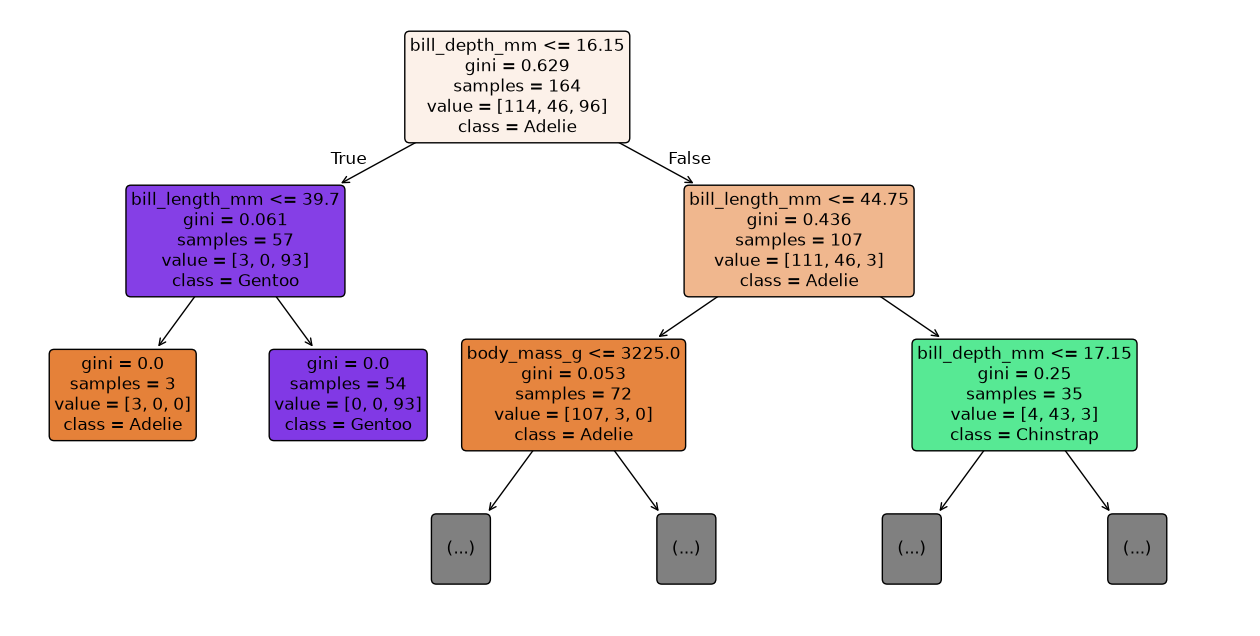

In [12]:
forest = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)

# 1. Fit forest on X_train, y_train.
forest.fit(X_train, y_train)

# 2. Predict X_train and X_test. Use accuracy_score for both accuracies.
#    Save the test score as forest_test_acc.
train_predictions = forest.predict(X_train)
test_predictions = forest.predict(X_test)

forest_train_acc = accuracy_score(y_train, train_predictions)
forest_test_acc = accuracy_score(y_test, test_predictions)

print("Training Accuracy:", round(forest_train_acc, 3))
print("Test Accuracy:", round(forest_test_acc, 3))

# 3. Print confusion_matrix(y_test, test_predictions,
#    labels=sorted(y.unique())) so rows/columns follow species order.
cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=sorted(y.unique())
)

print("Confusion Matrix:")
print(cm)

# 4. Get depths: [estimator.get_depth() for estimator in forest.estimators_].
#    Print the list, min(depths), max(depths), and np.mean(depths).
depths = [estimator.get_depth() for estimator in forest.estimators_]

print('Tree depths:', depths)
print("Minimum depth:", min(depths))
print("Maximum depth:", max(depths))
print("Average depth:", round(np.mean(depths), 3))

# 5. Compare forest_test_acc with tree_test_acc from Task 4.
print("Tuned Tree Test Accuracy:", round(tree_test_acc, 3))
print("Random Forest Test Accuracy:", round(forest_test_acc, 3))

# 6. Plot forest.estimators_[0] with plot_tree; use max_depth=2 to
#    show only its top levels, plus X.columns and sorted(y.unique()).
plt.figure(figsize=(16,8))

plot_tree(
    forest.estimators_[0],
    max_depth=2,
    feature_names=X.columns,
    class_names=[str(c) for c in forest.classes_],
    filled=True,
    rounded=True
)
plt.show()

Forest training accuracy: ___  Test accuracy: ___
Tree depths (min / max / mean): ____________________
What does the depth range tell you about the forest's trees? __________________________

## 6. Feature importance (3 min)
* A fitted forest exposes `feature_importances_`, one score per input measurement. 
* Label them with `pd.Series(scores, index=X.columns)`, sort descending, and plot them.
* Importance describes model use; it is not evidence that a measurement causes a penguin to belong to a species.

Top 5 importance features:
bill_length_mm       0.407454
flipper_length_mm    0.271490
bill_depth_mm        0.252864
body_mass_g          0.068193
dtype: float64


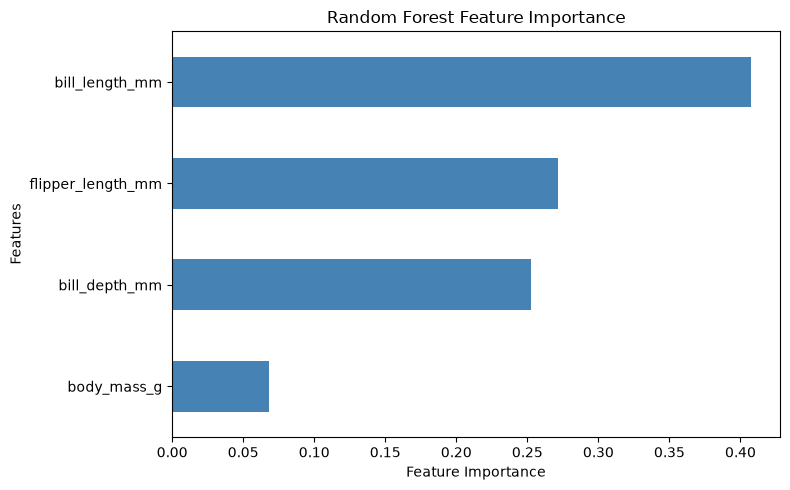

In [13]:
# Create a Series from forest.feature_importances_ and label it with X.columns.
importance = pd.Series(
    forest.feature_importances_,
    index = X.columns
)

# Sort descending, then plot those values.
importance = importance.sort_values(ascending=False)

print("Top 5 importance features:")
print(importance.head(5))

ax = importance.head(5).plot(
    kind='barh',
    figsize=(8,5),
    color='steelblue',
)

ax.invert_yaxis()

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

# Hint: .sort_values(ascending=False), .head(5), and .plot(kind='barh')

Top feature: bill_length_mm 

Why is this not causal evidence? 

## 7. Check your understanding (6 minutes, 10 marks)
Select one answer for each question. Answers should reflect the code and experiments in this lab. Record letters in the final answer cell.

**1. What does `stratify=y` do in the train/test split?**
* A. Sorts all examples by label
* B. Keeps class proportions approximately similar in both subsets
* C. Removes features that are not useful
* D. Makes the model deterministic by itself

**2. Why do we evaluate the fitted models on `X_test`?**
* A. To estimate performance on examples not used for fitting
* B. To increase training accuracy
* C. To select features before splitting
* D. To calculate feature names

**3. What does `max_depth=2` limit?**
* A. Number of input features
* B. Number of examples in the dataset
* C. Maximum number of decision levels in the tree
* D. Number of classes

**4. What can much higher training accuracy than test accuracy indicate?**
* A. Training and test accuracy are both low and similar
* B. The tree may be overfitting the training examples
* C. The tree has feature names
* D. The train/test split is stratified

**5. In a decision tree plot, what does a path from the root to a leaf describe?**
* A. A sequence of feature conditions leading to a prediction
* B. A sequence of training/test splits
* C. The importance ranking of every feature
* D. The number of trees in a forest

**6. What does `n_estimators=100` specify for a random forest?**
* A. Maximum depth of each tree
* B. Number of trees in the ensemble
* C. Number of features in the dataset
* D. Percentage used for testing

**7. How does a random forest make a classification prediction?**
* A. It uses only the first tree
* B. It combines the predictions of its trees, typically by voting
* C. It averages the feature names
* D. It chooses the prediction with the lowest training accuracy

**8. In `confusion_matrix(y_test, predictions)`, what does the cell at row 0, column 1 count?**
* A. True Adelie predicted as Chinstrap
* B. True Chinstrap predicted as Adelie
* C. Correct Adelie predictions
* D. True Gentoo predicted as Gentoo

**9. What is a reasonable interpretation of forest feature importance?**
* A. It proves the feature causes the target
* B. It summarizes feature use by this fitted forest, but does not prove causation
* C. It is the accuracy of the feature by itself
* D. It gives the predicted species for one penguin

**10. Which comparison is fairest in this lab?**
* A. Compare models using the same held-out test set
* B. Compare one model's training score with the other's test score
* C. Compare models trained on different splits
* D. Compare their number of printed tree rules


In [14]:
answers = ['B', 'A', 'C', 'B', 'A', 'b', 'B', 'a', 'B', 'a']  # Enter A, B, C, or D
assert len(answers) == 10
print('Answers recorded:', answers)

Answers recorded: ['B', 'A', 'C', 'B', 'A', 'b', 'B', 'a', 'B', 'a']


## Exit reflection (1 minute)
In one sentence: when would you prefer a shallow decision tree for this lab, and when might you prefer the random forest?

Your response: 
I would prefer a shallow decision tree when interpretability and simplicity are important, and a random forest when I need better generalization and more stable predictions, even though it is harder to interpret.